# Notebook 01 — Deep Learning Fundamentals & Model Selection

**Project:** ML Model Benchmark Lab  
**Purpose:** A practical, reusable reference for understanding deep learning, recognizing major neural-network architectures, and choosing suitable models for different data types and tasks.


## Learning outcomes

By the end, one should be able to:
1. Explain deep learning and how it relates to machine learning.
2. Describe neurons, layers, weights, activations, loss, backpropagation, and optimization.
3. Recognize major deep-learning architecture families and their use cases.
4. Choose a reasonable model family for tabular data, images, text, audio, sequences, graphs, and generative tasks.
5. Explain training, validation, testing, transfer learning, overfitting, and data leakage.
6. Run a small neural-network example and interpret its evaluation.
7. Design a fair experiment comparing deep-learning models.

### How to use this notebook
Read the explanations, run the code and write concepts in your own words. Model-selection advice is a starting hypothesis—not a guarantee that a model will win.

## Contents
1. Deep learning and its relationship to ML
2. Neural-network building blocks
3. Model architectures and types
4. Which model suits which data/task?
5. How neural networks learn
6. The deep-learning workflow
7. Metrics and common pitfalls
8. Practical example: a small neural network
9. Glossary
10. References

---

## 1. What is deep learning?

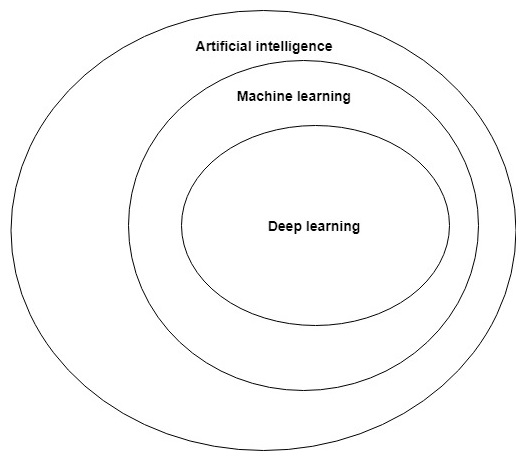

**Deep learning (DL)** is a subfield of machine learning that uses neural networks with multiple layers to learn representations and make predictions.

A simplified relationship is **Artificial Intelligence → Machine Learning → Deep Learning**:
- **AI:** the broad field of systems performing tasks associated with intelligent behavior.
- **ML:** systems learn patterns from data rather than relying only on manually written rules.
- **DL:** ML methods using multilayer neural networks.

Deep learning is influential in image recognition, speech, natural-language processing, recommendation, scientific modeling, and generative AI. It is **not automatically the best choice for every problem**: classical methods such as gradient-boosted trees can be strong on small structured/tabular datasets.

### Traditional features vs. learned representations
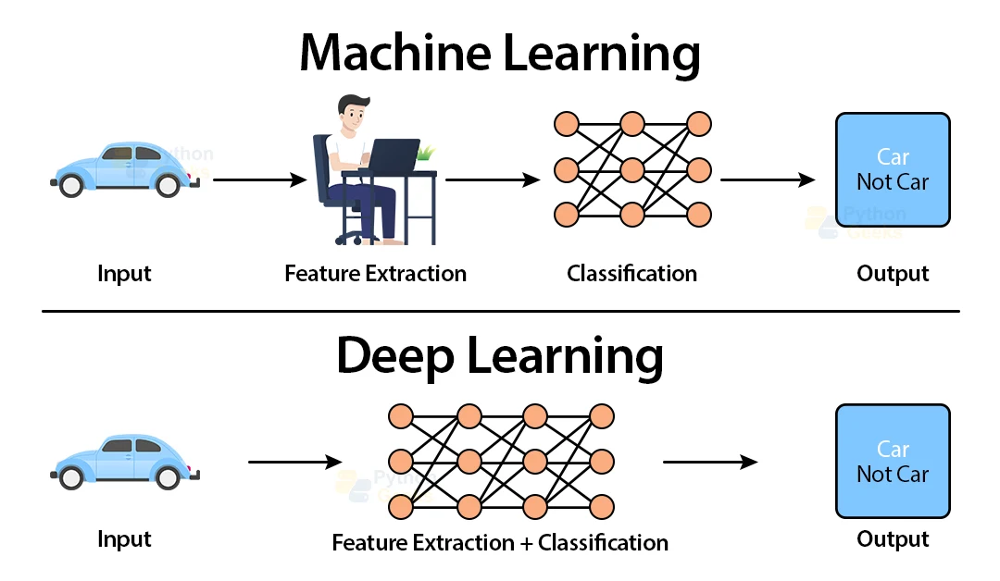
Traditional ML workflows often rely more on manually designed features. Deep networks can learn intermediate representations from raw or lightly processed inputs.

- **Image:** pixels → local patterns → shapes/parts → class scores.
- **Text:** tokens → contextual representations → class labels or generated tokens.
- **Audio:** waveform or spectrogram → acoustic patterns → speech or audio labels.

These are intuitive illustrations, not a strict description of every architecture.

| Aspect | Traditional ML (broadly) | Deep learning |
|---|---|---|
| Feature engineering | Often relies more on manually designed features | Can learn representations |
| Data needs | Many methods work well on smaller datasets | Often benefits from more data; pretrained models can help |
| Compute | Often modest | Can be substantial for large networks |
| Unstructured data | Needs useful representations/features | Particularly effective for images, text, audio |
| Interpretability | Varies by model | Often harder to interpret directly |

### When should you consider DL?
Consider it when the input is complex, learned representations may help, enough data/compute or a pretrained model is available, or transfer learning is suitable. Start with a simpler baseline when data is small, features are informative, compute is limited, or interpretability is critical.



---

## 2. Neural-network building blocks
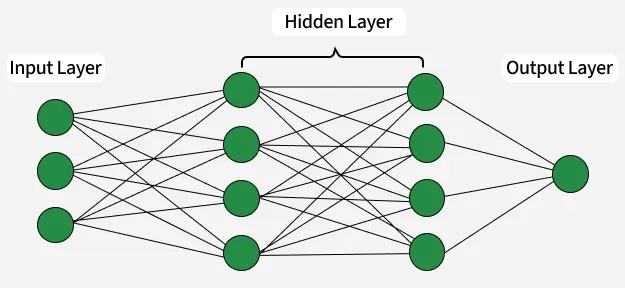

A neural network is a parameterized function. Training adjusts parameters so predictions better match targets according to a loss function.

### 2.1 Neurons, weights, and biases
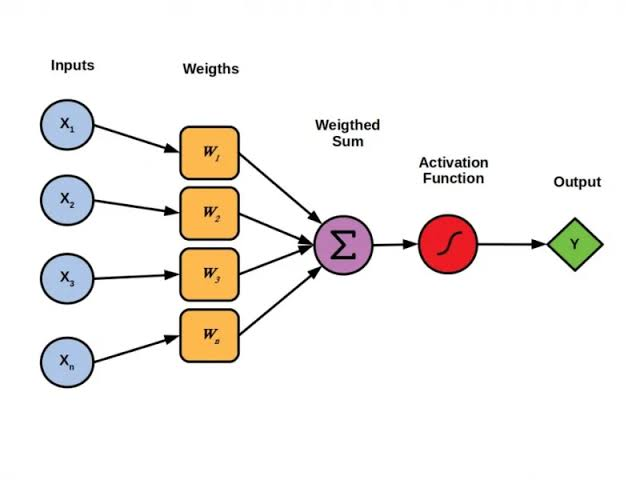

A simplified neuron computes a weighted sum, adds a bias, then applies an activation:

\[
z = \sum_{i=1}^{n} w_i x_i + b,\qquad a = \phi(z)
\]

- `x`: inputs
- `w`: learnable weights
- `b`: learnable bias
- `φ`: activation function
- `a`: output of the unit

### 2.2 Layers
- **Input layer:** receives data.
- **Hidden layers:** transform representations.
- **Output layer:** produces scores, probabilities, values, or other task-specific outputs.

More layers do not automatically mean a better model.

### 2.3 Common activations

| Activation | Typical role | Intuition / caution |
|---|---|---|
| ReLU | Hidden layers | Zeros negative values; simple and efficient |
| Sigmoid | Binary probability output or gating | Maps values to 0–1; can saturate |
| Softmax | Multiclass probabilities | Turns class scores into values summing to 1 |
| Tanh | Some hidden/state representations | Maps values to −1 through 1; can saturate |
| GELU | Transformer blocks | Smooth nonlinear activation |

The output activation and loss must match the task. For example, multiclass classification often uses logits with a cross-entropy loss.

### 2.4 Loss, backpropagation, and optimization
- **Loss:** measures error according to the training objective.
- **Forward pass:** computes predictions.
- **Backpropagation:** calculates gradients showing how parameters affect the loss.
- **Optimizer:** updates parameters using gradients (e.g. SGD, Adam).
- **Epoch:** one pass through the training data.
- **Batch:** subset processed in one training step.
- **Learning rate:** controls update size.

Loss is not the same as the final evaluation metric. A model can train with cross-entropy but be evaluated using macro F1 or recall.


---

## 3. Major deep-learning model architectures

Architecture describes the structure of a neural network. Different architectures encode different assumptions about data: local patterns in images, order in sequences, or relationships in graphs.

### 3.1 MLP / Feedforward Neural Network

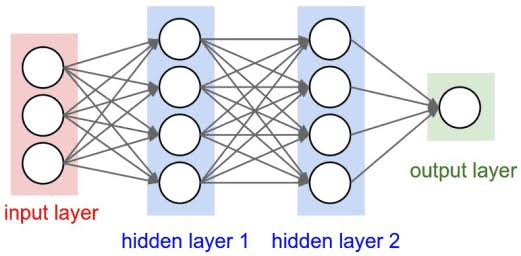

**Best suited for:** fixed-length numeric feature vectors; a learning baseline for classification or regression.  
**Intuition:** fully connected layers transform input values into outputs.  
**Strengths:** simple and flexible.  
**Limitations:** does not automatically exploit image locality or sequence structure; can be outperformed by classical models on small tabular data.  
**Example:** predict a numeric value from engineered features.

### 3.2 Convolutional Neural Network (CNN)
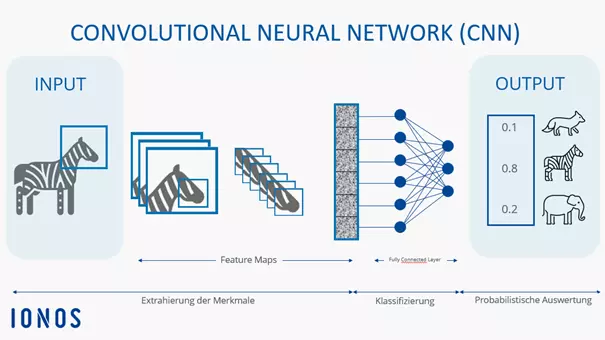

**Best suited for:** images and other data with local spatial structure; sometimes spectrograms or time series.  
**Intuition:** convolutional filters detect local patterns and reuse weights across locations.  
**Strengths:** effective for spatial patterns and parameter sharing.  
**Limitations:** training from scratch can need substantial labeled data; pretrained vision models can help.  
**Example:** classify plant-leaf images or recognize handwritten digits.

### 3.3 RNN, LSTM, and GRU
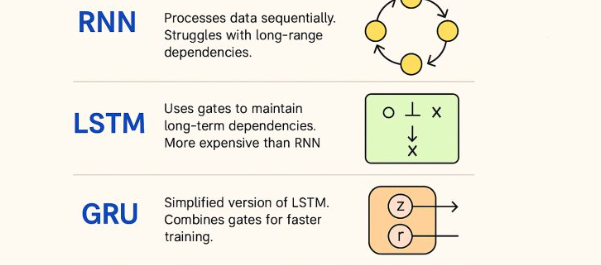

**Best suited for:** sequential data where order matters, especially classic sequence-learning settings.  
**Intuition:** process sequence elements while maintaining a hidden state; LSTM/GRU use gates to manage information.  
**Strengths:** naturally process sequences; useful in some streaming or resource-constrained applications.  
**Limitations:** sequential computation is harder to parallelize; long-range dependencies can be challenging; Transformers are often preferred for modern large-scale NLP.  
**Example:** sensor-sequence classification.

### 3.4 Transformer

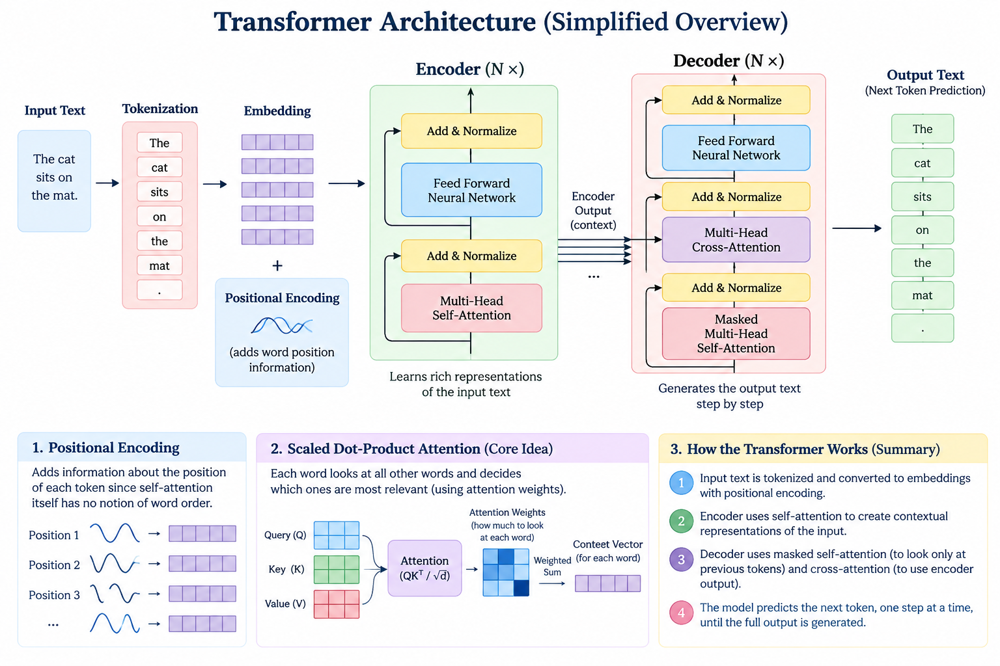

**Best suited for:** text, code, and increasingly images, audio, video, and multimodal data.  
**Intuition:** attention lets representations incorporate information from other positions.  
**Strengths:** highly effective for language; pretrained models can be adapted to new tasks.  
**Limitations:** memory and compute can be substantial; full attention becomes expensive for long sequences; licensing and training-data constraints matter.  
**Example:** fine-tune a pretrained encoder for sentiment classification or use a decoder-only model for text generation.

### 3.5 Autoencoder

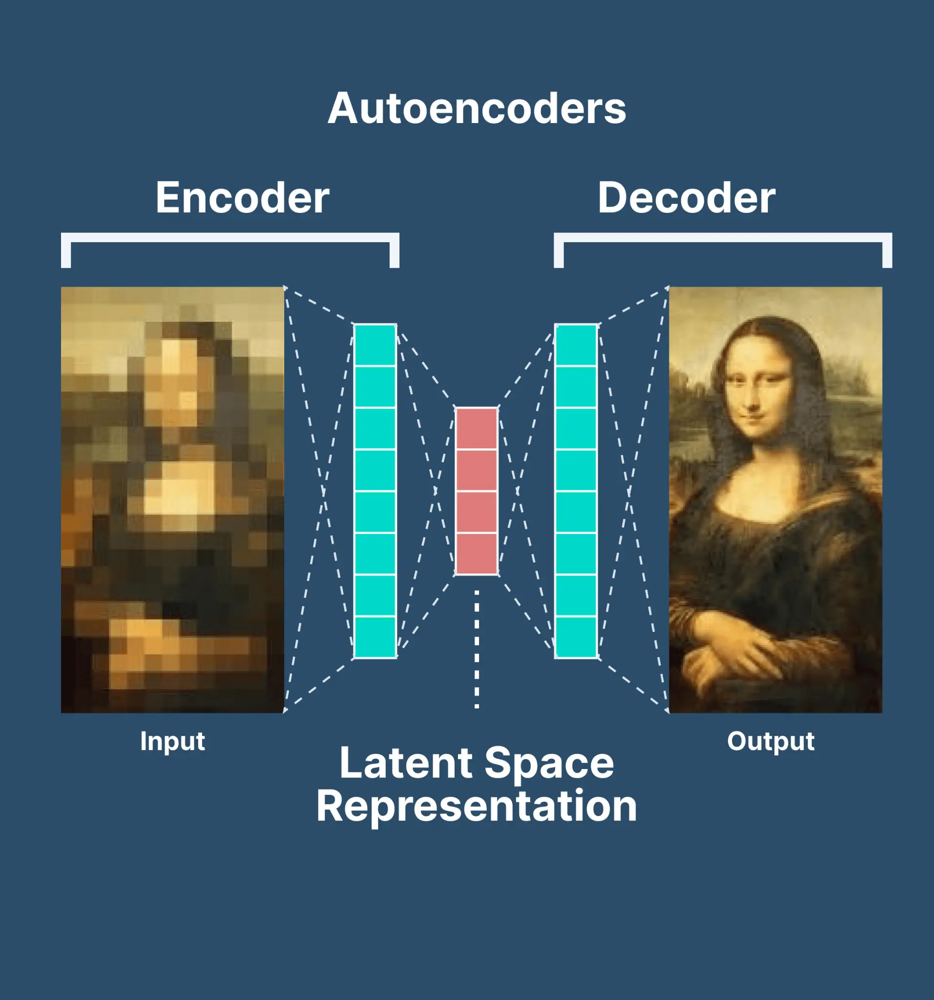


**Best suited for:** compact representations, reconstruction, and some anomaly-detection setups.  
**Intuition:** an encoder compresses input; a decoder reconstructs it.  
**Strengths:** can learn representations without class labels.  
**Limitations:** reconstruction quality does not automatically make a useful anomaly detector; thresholds and training data matter.  
**Example:** investigate sensor readings with unusually high reconstruction error.

### 3.6 Generative Adversarial Network (GAN)

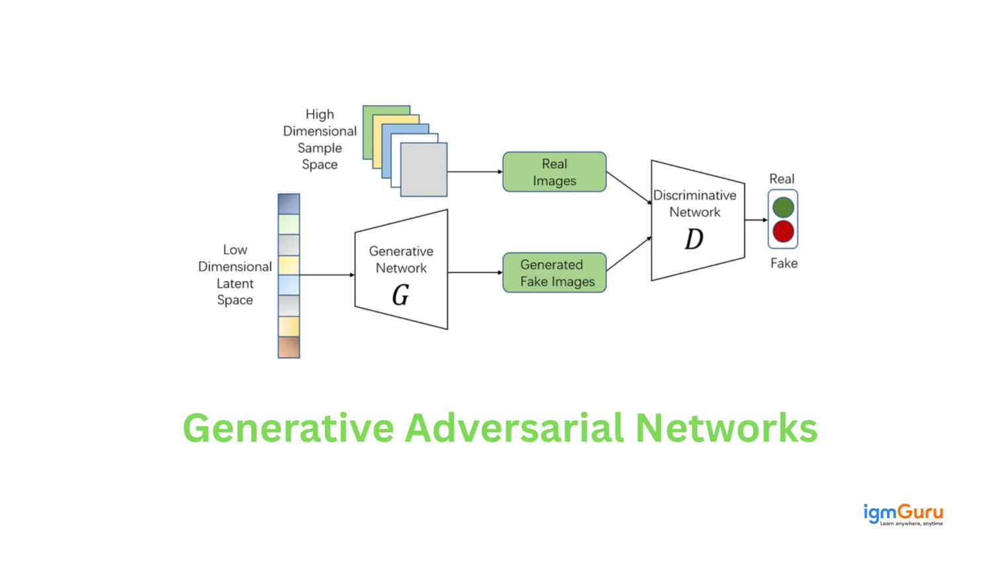

**Best suited for:** generating synthetic data in some image-generation tasks.  
**Intuition:** a generator creates samples while a discriminator distinguishes generated from real samples.  
**Strengths:** can generate realistic samples in suitable settings.  
**Limitations:** training can be unstable; mode collapse and evaluation are challenging.  
**Example:** experimental synthetic-image generation.

### 3.7 Diffusion models

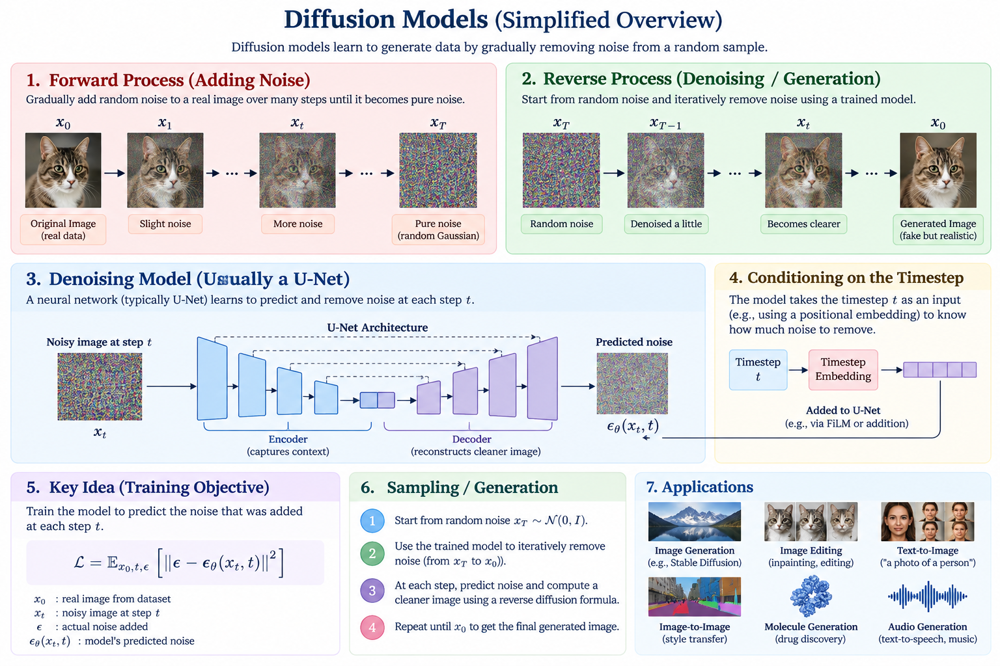

**Best suited for:** image, audio, video, and other content generation in suitable systems.  
**Intuition:** learn to reverse a gradual noising process.  
**Strengths:** powerful generation quality and flexible conditioning in many systems.  
**Limitations:** iterative generation and training can require substantial compute.  
**Example:** text-conditioned image generation or inpainting.

### 3.8 Graph Neural Networks (GNNs)

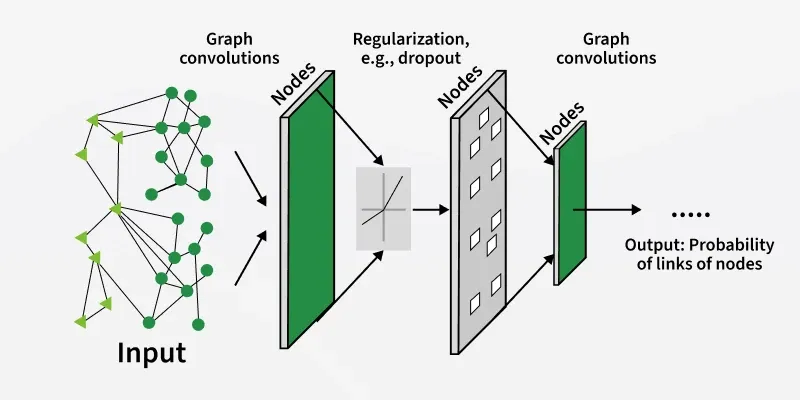

**Best suited for:** data represented as nodes and edges where relationships matter.  
**Intuition:** nodes update representations by aggregating information from neighbors.  
**Strengths:** explicitly use graph structure.  
**Limitations:** results depend on graph quality; scaling and oversmoothing can be challenging.  
**Example:** node classification in a citation network or property prediction on molecular graphs.

### 3.9 Siamese networks / metric learning

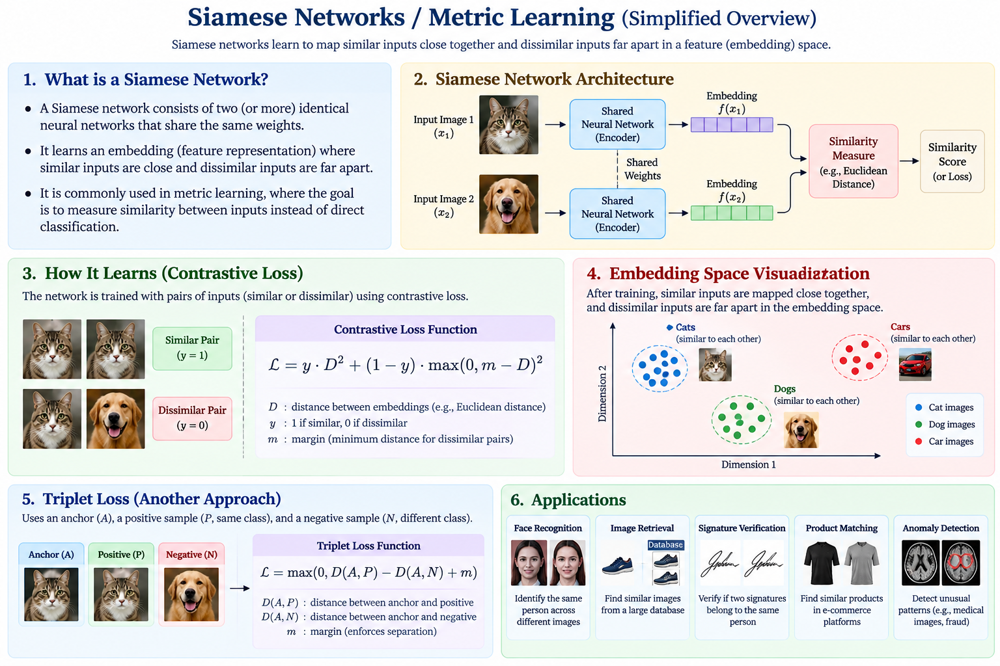

**Best suited for:** similarity, verification, and retrieval.  
**Intuition:** shared network branches map examples into an embedding space where related items are close.  
**Strengths:** useful for matching and similarity search.  
**Limitations:** pair/triplet sampling and evaluation can be difficult.  
**Example:** finding visually similar products.

### 3.10 Deep reinforcement learning

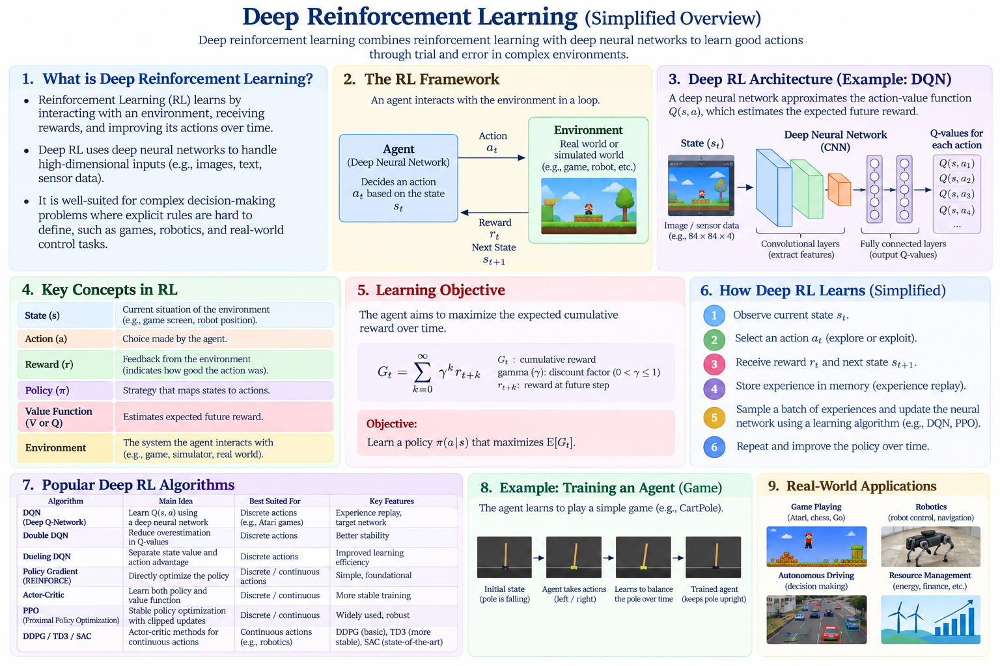

**Best suited for:** sequential decision problems with complex observations and reward signals.  
**Intuition:** neural networks approximate a policy, value function, or related component.  
**Strengths:** can handle high-dimensional observations in interactive environments.  
**Limitations:** often sample-inefficient and sensitive to experimental setup.  
**Example:** an agent learning to play a game from rewards.



### Architecture vs. learning setup vs. task
- **Architecture:** CNN, Transformer, MLP, GNN.
- **Learning setup:** supervised, self-supervised, reinforcement learning.
- **Training strategy:** train from scratch, feature extraction, fine-tuning.
- **Task:** classification, regression, generation, retrieval, segmentation, forecasting.

A Transformer may be used for classification or generation. A CNN may be trained with labels or pretrained and fine-tuned. These categories are related but not interchangeable.

---

## 4. Which model suits which data and task?

Use this as a first-choice guide, not a fixed rule. It includes non-DL baselines because choosing deep learning should itself be justified.

| Data / task | First candidates | Why / caveat |
|---|---|---|
| Small numeric tabular data | Gradient-boosted trees, Logistic Regression; MLP as comparison | DL is not automatically best for small tabular datasets |
| Complex tabular data | Gradient boosting and MLP/modern tabular methods | Benchmark; preprocessing and validation matter |
| Image classification | CNN or pretrained vision Transformer | Transfer learning is often practical |
| Image segmentation | U-Net-style CNN or segmentation Transformer | Requires masks and segmentation metrics |
| Object detection | YOLO-family, Faster R-CNN, DETR-family approaches | Requires box/instance annotations and task-specific metrics |
| Text classification | TF-IDF + Logistic Regression/Linear SVM; pretrained Transformer | Establish a simple baseline first |
| Text generation | Pretrained decoder-style language model | Prompting vs fine-tuning depends on goal/resources |
| Speech recognition | Pretrained speech Transformer or suitable speech model | Language, noise, preprocessing, and latency matter |
| Time-series forecasting | Naive/seasonal baseline, classical forecasting, RNN/TCN/Transformer candidates | Preserve time order to avoid future leakage |
| Graph prediction | GNN or graph-specific baseline | Graph construction and split strategy matter |
| Similarity/retrieval | Siamese/contrastive embedding model; pretrained embeddings | Evaluate retrieval or verification metrics |
| Image/audio generation | Diffusion or another generative family | High compute and careful quality/safety evaluation |
| Sequential decisions | RL methods, sometimes deep RL | Use when interaction and rewards are part of the problem |

### A practical decision sequence
1. Identify data modality and target.
2. Establish a simple baseline.
3. Check dataset size, labels, compute, latency, and interpretability.
4. Choose a suitable architecture family—not simply the newest model.
5. Consider pretrained weights when appropriate and legally usable.
6. Evaluate on data reflecting intended deployment.
7. Compare performance, cost, reliability, and limitations.

### Training from scratch vs. transfer learning
**Training from scratch** can make sense with enough representative data, a need for control, or when studying the learning process.

**Transfer learning** starts from a model pretrained on other data. You may freeze it as a feature extractor, fine-tune some layers, or fine-tune the whole model. It is often useful for image and language tasks with limited labels, but domain mismatch, pretrained data, licensing, and evaluation still matter.

---

## 5. How neural networks learn

For an image classifier:
1. An image becomes a numeric tensor.
2. The network produces class scores.
3. A loss function compares scores with the correct label.
4. Backpropagation calculates gradients.
5. An optimizer updates weights.
6. Training repeats across batches and epochs.
7. Validation helps detect overfitting and select settings/checkpoints.

| Term | Meaning |
|---|---|
| Parameters | Values learned by the network, such as weights and biases |
| Hyperparameters | Settings such as learning rate, batch size, and layer size |
| Epoch | One pass through the training set |
| Batch size | Examples processed in one training step |
| Learning rate | Controls optimizer update size |
| Optimizer | Update rule, e.g. SGD or Adam |
| Regularization | Techniques that discourage overfitting |
| Dropout | Randomly disables units during training in some architectures |
| Early stopping | Stops training when validation performance stops improving |
| Checkpoint | Saved model state, often the best validation model |

### Common problems
- **Overfitting:** training performance improves while validation performance is much weaker or worsens.
- **Underfitting:** model is too limited or poorly configured to learn useful patterns.
- **Vanishing/exploding gradients:** gradients become extremely small or large.
- **Class imbalance:** the model may favor common classes.
- **Distribution shift:** future data differs from training data.

Possible remedies include better data, appropriate architecture, normalization, regularization, transfer learning, learning-rate schedules, and careful validation. Diagnose the cause rather than applying everything at once.

---

## 6. The deep-learning workflow

1. **Define the task and success criteria.**
2. **Inspect data:** source, labels, class balance, duplicates, length/resolution, permissions.
3. **Create leakage-safe train/validation/test partitions.** Split by subject, group, or time when appropriate.
4. **Build a baseline:** simple rule, classical model, or small neural network.
5. **Prepare inputs:** scale numeric features/pixels, tokenize text, process audio, or build graph representations.
6. **Choose architecture and loss** to match the task.
7. **Train on training data** and track loss/metrics.
8. **Use validation for choices:** tune hyperparameters, select checkpoints, apply early stopping.
9. **Evaluate the selected model on the held-out test set.**
10. **Analyze errors and robustness.**
11. **Document compute and reproducibility:** versions, seeds, preprocessing, hardware, checkpoint, limitations.

### Train / validation / test
A common setup is 70/15/15 or 80/10/10; an 80/20 train-test split can also work if validation is created within the 80% training portion (for example, with cross-validation).

- **Training:** fits parameters.
- **Validation:** selects architectures, hyperparameters, epochs, and checkpoints.
- **Test:** estimates final performance after choices are made.

Do not use the test set to tune the model. For time series, preserve chronology. For multiple records from the same patient/person, split by person when appropriate.

### Leakage-safe preprocessing
Fit data-dependent preprocessing only on training data, then apply the fitted transformation to validation/test data. Keep related observations and near-duplicates in the same partition when necessary. Avoid inputs containing labels or future information unavailable at prediction time.

---

## 7. Evaluation metrics and common pitfalls

### Classification
- **Accuracy:** fraction correct overall.
- **Precision:** among predicted positives, fraction truly positive.
- **Recall:** among actual positives, fraction detected.
- **F1:** harmonic mean of precision and recall.
- **Macro F1:** treats each class equally.
- **ROC-AUC / PR-AUC:** ranking metrics for appropriate settings; PR-AUC can be informative when positive examples are rare.
- **Confusion matrix:** reveals which classes are confused.

### Regression
- **MAE:** average absolute error.
- **MSE / RMSE:** penalizes larger errors more heavily; RMSE is in target units.
- **R²:** comparison with a mean-prediction reference; it is not percentage accuracy and can be negative on test data.

### Other tasks
- **Segmentation:** IoU and Dice.
- **Object detection:** mAP at specified IoU thresholds.
- **Generation:** no single automatic metric captures quality, diversity, usefulness, safety, and memorization.

### Report practical costs too
Where relevant, record training time, inference latency, memory, model size/parameter count, variance across seeds, and data requirements. A slightly lower-scoring model may be preferable if it is faster, smaller, more reliable, or easier to maintain.

### Common pitfalls
- **Data leakage:** information unavailable at prediction time contaminates training/evaluation.
- **Test-set overuse:** repeatedly adjusting models based on test results undermines final evaluation.
- **Unfair comparisons:** different splits, preprocessing, tuning budgets, or pretrained data may confound results.
- **Class imbalance:** accuracy can hide poor minority-class performance.
- **Distribution shift:** good test results may not transfer to future data.
- **Overclaiming:** predictive association does not establish causation or clinical validity.

---

## 8. Practical example: train a small neural network

This example uses scikit-learn's `MLPClassifier` on the Breast Cancer Wisconsin dataset. It demonstrates the training workflow; it does **not** claim an MLP is the best model for this dataset.

We will:
1. create a stratified 80/20 train-test split;
2. scale features inside a pipeline;
3. train a small MLP;
4. compare it with a Dummy Classifier baseline;
5. inspect metrics and a confusion matrix.

This fixed configuration is for learning. A rigorous experiment would select settings using validation or cross-validation and evaluate the chosen setup on the test set once.

Dataset shape: (569, 30)
Target names: ['malignant', 'benign']

Class counts:
target
0    212
1    357
Name: count, dtype: int64


,model,accuracy,balanced_accuracy
0,Dummy baseline,0.632,0.500
1,Scaled MLP,0.921,0.938


MLP classification report:
              precision    recall  f1-score   support

   malignant       0.82      1.00      0.90        42
      benign       1.00      0.88      0.93        72

    accuracy                           0.92       114
   macro avg       0.91      0.94      0.92       114
weighted avg       0.93      0.92      0.92       114



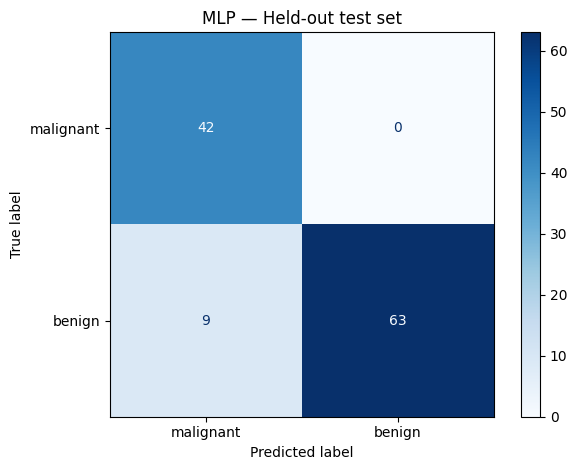

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# 1. Load data
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

print("Dataset shape:", X.shape)
print("Target names:", list(data.target_names))
print("\nClass counts:")
print(y.value_counts().sort_index())

# 2. Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# 4. Scale features inside a pipeline and train an MLP
mlp = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=0.001,
        max_iter=1000,
        early_stopping=True,
        random_state=42,
    ),
)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)

# 5. Compare metrics
results = pd.DataFrame([
    {
        "model": "Dummy baseline",
        "accuracy": accuracy_score(y_test, baseline_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, baseline_pred),
    },
    {
        "model": "Scaled MLP",
        "accuracy": accuracy_score(y_test, mlp_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test, mlp_pred),
    },
])
display(results.round(3))

print("MLP classification report:")
print(classification_report(
    y_test, mlp_pred, target_names=data.target_names, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, mlp_pred, display_labels=data.target_names, cmap="Blues"
)
plt.title("MLP — Held-out test set")
plt.tight_layout()
plt.show()

### Interpret the example

After running the cell, answer:
1. Did the MLP improve on the Dummy Classifier?
2. Which class has lower recall?
3. What does the confusion matrix reveal?
4. Why do we scale features for this MLP?
5. Why is one test score not enough to prove MLP is the best model?
6. What extra evidence would be required before making a medical claim?

**Cautions**
- Check `target_names`; do not assume which numeric target corresponds to which class.
- This is an educational example, not a validated diagnostic tool.
- A single split can be variable; use cross-validation for comparisons.
- Repeatedly tuning based on this test set makes it part of model selection.

---

## 9. Glossary

| Term | Quick definition |
|---|---|
| Neural network | Parameterized function built from connected computational units |
| Layer | Stage of transformations in a network |
| Weight / bias | Learnable parameters |
| Activation | Transformation applied to a unit's output |
| Forward pass | Computing predictions from inputs |
| Loss | Training objective measuring prediction error |
| Backpropagation | Computing gradients through the network |
| Optimizer | Rule for updating parameters |
| Epoch | One pass through training data |
| Batch | Subset used in a training step |
| Hyperparameter | Setting chosen outside ordinary parameter fitting |
| Regularization | Methods to discourage overfitting |
| CNN | Convolutional Neural Network |
| RNN / LSTM / GRU | Recurrent sequence-model families |
| Transformer | Architecture based on attention and related blocks |
| Autoencoder | Encoder-decoder model trained to reconstruct input |
| GNN | Graph Neural Network |
| Transfer learning | Reusing a pretrained model for a related task |
| Fine-tuning | Continuing training of a pretrained model on task data |
| Inference | Using a trained model to produce outputs |
| Checkpoint | Saved model state |
| Data leakage | Improper information contaminating learning/evaluation |


## 10. References
- [Dive into Deep Learning](https://d2l.ai/)
- [TensorFlow tutorials](https://www.tensorflow.org/tutorials)
- [PyTorch tutorials](https://pytorch.org/tutorials/)
- [Keras guides](https://keras.io/guides/)
- [The Illustrated Transformer](https://jalammar.github.io/illustrated-transformer/)
- [Scikit-learn: Neural network models](https://scikit-learn.org/stable/modules/neural_networks_supervised.html)

**Project note:** This is an educational guide. Model suitability depends on data, objectives, resources, and evaluation; choices should be treated as hypotheses to test.